# IN1002B: DESARROLLO DE PROYECTOS DE ANÁLISIS DE DATOS

## Contenido

1. Leer archivo
1. Preprocesar los datos
1. Análisis y Visualización

In [1]:
# importamos librerías
import warnings
warnings.filterwarnings("ignore")

In [2]:

import numpy as np # librería para poder usar arreglos
import pandas as pd # librería para poder usad DataFrames (tablas)
import matplotlib.pyplot as plt # to plot
import seaborn as sns # to plot

## 1. Leer archivo

In [3]:
dataSet = pd.read_csv("most_watched_anime_dataset_100_entries.csv", header=0)

In [4]:
print(dataSet.head())
print("")
print(dataSet.info())
print("")
print(dataSet.isnull().sum())
print("")
print(dataSet.describe())

            Anime Name Most Watched in Country  Ratings  Number of Episodes  \
0  Fullmetal Alchemist                  Brazil      8.8               317.0   
1            Haikyuu!!                  Mexico      9.2               420.0   
2                  NaN             South Korea      7.4               419.0   
3               Bleach                  Brazil      6.4                 NaN   
4     Sword Art Online                     NaN      9.8               327.0   

  Animation Studio Name  Budget (in Million USD)  Release Year      Genre  \
0              Ufotable                    80.61        1998.0    Fantasy   
1                 MAPPA                    74.99        2022.0  Adventure   
2          A-1 Pictures                    59.05        2009.0    Mystery   
3              Ufotable                    45.35        2002.0    Fantasy   
4              Madhouse                    15.90        2017.0        NaN   

   Duration per Episode (minutes)  
0                         

## 2. Preprocesar los datos

In [5]:
filter_data = dataSet[dataSet["Number of Episodes"].notna()]
print(filter_data.head())
print("")
print(filter_data.info())
print("")
print(filter_data.isnull().sum())
print("")
print(filter_data.describe())

            Anime Name Most Watched in Country  Ratings  Number of Episodes  \
0  Fullmetal Alchemist                  Brazil      8.8               317.0   
1            Haikyuu!!                  Mexico      9.2               420.0   
2                  NaN             South Korea      7.4               419.0   
4     Sword Art Online                     NaN      9.8               327.0   
5  Fullmetal Alchemist                  Brazil      NaN               402.0   

  Animation Studio Name  Budget (in Million USD)  Release Year      Genre  \
0              Ufotable                    80.61        1998.0    Fantasy   
1                 MAPPA                    74.99        2022.0  Adventure   
2          A-1 Pictures                    59.05        2009.0    Mystery   
4              Madhouse                    15.90        2017.0        NaN   
5                   NaN                     8.97        2018.0        NaN   

   Duration per Episode (minutes)  
0                         

In [6]:
print(dataSet.describe())
print("")
print(filter_data.describe())

         Ratings  Number of Episodes  Budget (in Million USD)  Release Year  \
count  90.000000           90.000000                90.000000     90.000000   
mean    8.222222          250.722222                74.260778   2005.133333   
std     1.114035          138.047462                43.209005      9.967588   
min     6.200000           12.000000                 5.820000   1990.000000   
25%     7.200000          131.500000                38.220000   1995.500000   
50%     8.200000          275.000000                67.270000   2005.500000   
75%     9.350000          360.000000               110.827500   2014.000000   
max    10.000000          499.000000               149.390000   2022.000000   

       Duration per Episode (minutes)  
count                       90.000000  
mean                        39.888889  
std                         12.466084  
min                         20.000000  
25%                         29.250000  
50%                         39.000000  
75%     

In [7]:
df = dataSet.copy()
df = df[df["Most Watched in Country"].notna()]
df = df[df["Ratings"].notna()]
df = df[df["Animation Studio Name"].notna()]
df = df[df["Budget (in Million USD)"].notna()]

In [8]:
print(df.head())
print("")
print(df.info())
print("")
print(df.isnull().sum())
print("")
print(df.describe())

            Anime Name Most Watched in Country  Ratings  Number of Episodes  \
0  Fullmetal Alchemist                  Brazil      8.8               317.0   
1            Haikyuu!!                  Mexico      9.2               420.0   
2                  NaN             South Korea      7.4               419.0   
3               Bleach                  Brazil      6.4                 NaN   
7               Bleach                   China      9.4                47.0   

  Animation Studio Name  Budget (in Million USD)  Release Year      Genre  \
0              Ufotable                    80.61        1998.0    Fantasy   
1                 MAPPA                    74.99        2022.0  Adventure   
2          A-1 Pictures                    59.05        2009.0    Mystery   
3              Ufotable                    45.35        2002.0    Fantasy   
7                 MAPPA                   127.22        1995.0  Adventure   

   Duration per Episode (minutes)  
0                         

In [9]:
print(dataSet.describe())
print("")
print(filter_data.describe())
print("")
print(df.describe())

         Ratings  Number of Episodes  Budget (in Million USD)  Release Year  \
count  90.000000           90.000000                90.000000     90.000000   
mean    8.222222          250.722222                74.260778   2005.133333   
std     1.114035          138.047462                43.209005      9.967588   
min     6.200000           12.000000                 5.820000   1990.000000   
25%     7.200000          131.500000                38.220000   1995.500000   
50%     8.200000          275.000000                67.270000   2005.500000   
75%     9.350000          360.000000               110.827500   2014.000000   
max    10.000000          499.000000               149.390000   2022.000000   

       Duration per Episode (minutes)  
count                       90.000000  
mean                        39.888889  
std                         12.466084  
min                         20.000000  
25%                         29.250000  
50%                         39.000000  
75%     

## 3. Análisis y Visualización

### Hipótesis
El nivel de inversión de cada casa productora influye en que tengan mayor rating y mayor penetración en más países.

In [10]:
country_list = df["Most Watched in Country"].unique()
print(country_list)

['Brazil' 'Mexico' 'South Korea' 'China' 'Spain' 'United Kingdom'
 'Australia' 'Italy' 'Thailand' 'Argentina' 'India' 'Russia'
 'United States' 'Germany' 'Canada' 'France' 'Japan' 'Malaysia'
 'Philippines']


In [11]:
country_count = df["Most Watched in Country"].value_counts()
print(country_count)
print("")
print("Total: ", country_count.sum())

Most Watched in Country
Argentina         6
Germany           6
United States     5
Brazil            5
China             5
United Kingdom    4
Thailand          4
Mexico            4
Russia            4
France            4
Malaysia          4
Australia         3
Italy             3
India             3
Canada            3
Spain             2
Japan             2
South Korea       1
Philippines       1
Name: count, dtype: int64

Total:  69


In [12]:
print(df.shape)

(69, 9)


In [13]:
import random
import string

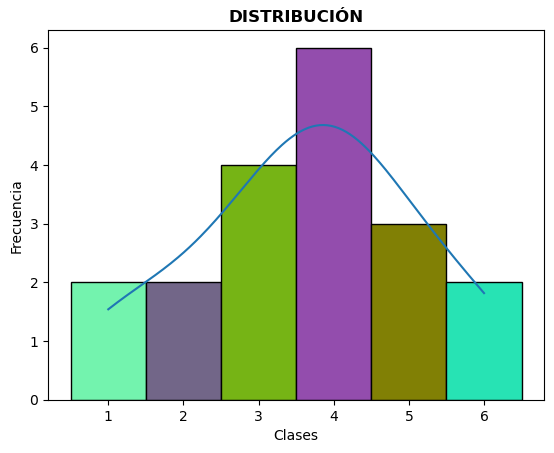

In [14]:
plt.figure()
ax = sns.histplot(country_count, kde=True, discrete=True)

patches = ax.patches

# Random facecolor for each bar
for i in range(len(patches)):
   patches[i].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
   # genera una lista de 6 caracteres aleatorios, combinando letras A-F y dígitos 0-9
   # representan un código de color hexadecimal, ejemplo: #A1B2C3

plt.title('DISTRIBUCIÓN', fontweight='bold')
plt.xlabel('Clases')
plt.ylabel('Frecuencia')
plt.show()

In [15]:
print(round(country_count.describe(),2))

count    19.00
mean      3.63
std       1.46
min       1.00
25%       3.00
50%       4.00
75%       4.50
max       6.00
Name: count, dtype: float64


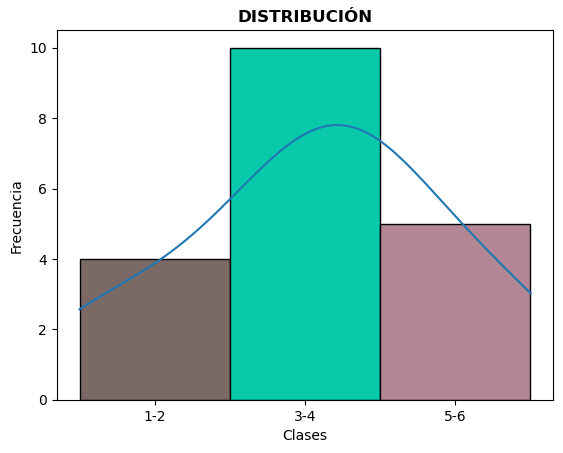

In [16]:
n_classes = 3

plt.figure()


ax = sns.histplot(country_count, bins=n_classes, kde=True)

# Random facecolor for each bar
patches = ax.patches
for i in range(len(patches)):
   patches[i].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))
   # genera una lista de 6 caracteres aleatorios, combinando letras A-F y dígitos 0-9
   # representan un código de color hexadecimal, ejemplo: #A1B2C3

centers = [p.get_x() + p.get_width() / 2 for p in patches]
ax.set_xticks(centers)
ax.set_xticklabels(["1-2", "3-4", "5-6"])

plt.title('DISTRIBUCIÓN', fontweight='bold')
plt.xlabel('Clases')
plt.ylabel('Frecuencia')
plt.show()

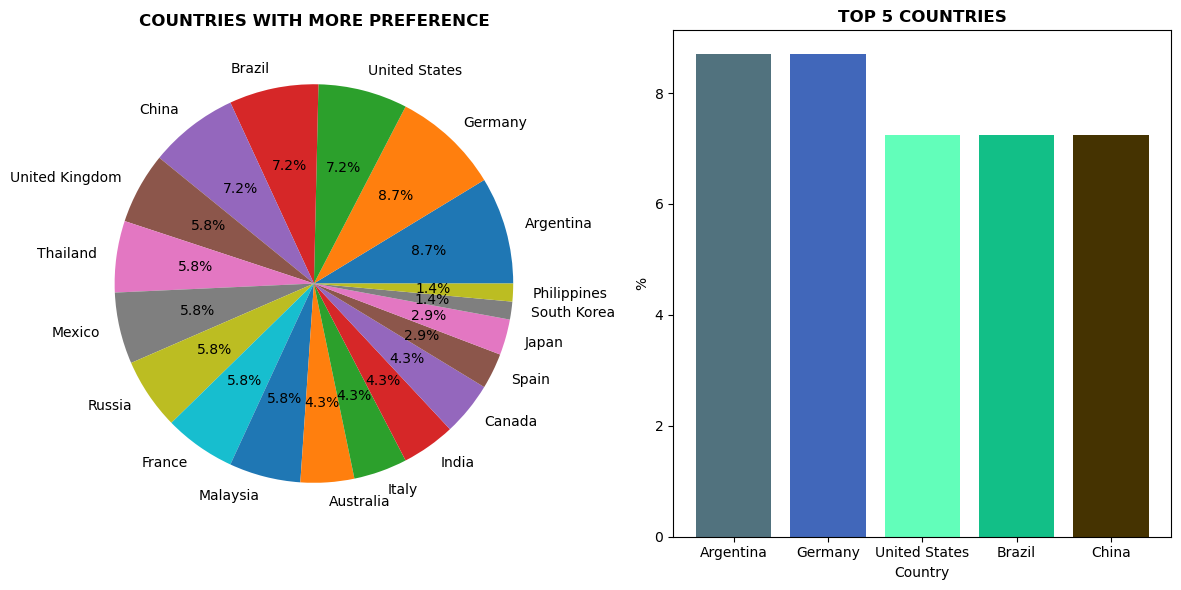

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].pie(country_count, labels=country_count.index, autopct='%1.1f%%')
ax[0].set_title('COUNTRIES WITH MORE PREFERENCE', fontweight='bold')

patches = ax[1].bar(country_count.index[0:5], country_count[0:5]/country_count.sum()*100)

# Random facecolor for each bar
for i in range(len(patches)):
   patches[i].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))

ax[1].set_title('TOP 5 COUNTRIES', fontweight='bold')
ax[1].set_xlabel('Country')
ax[1].set_ylabel('%')

plt.tight_layout()
plt.show()

In [18]:
rating_per_country = df.pivot_table(index="Most Watched in Country", values="Ratings", aggfunc="mean").sort_values(by="Ratings", ascending=False)
print(round(rating_per_country, 2))

                         Ratings
Most Watched in Country         
Thailand                    8.98
China                       8.92
Italy                       8.83
France                      8.80
Spain                       8.75
United Kingdom              8.57
Russia                      8.50
Brazil                      8.42
Argentina                   8.25
Malaysia                    8.18
Australia                   8.13
Germany                     7.95
India                       7.90
United States               7.80
Mexico                      7.80
Japan                       7.65
Canada                      7.50
South Korea                 7.40
Philippines                 7.00


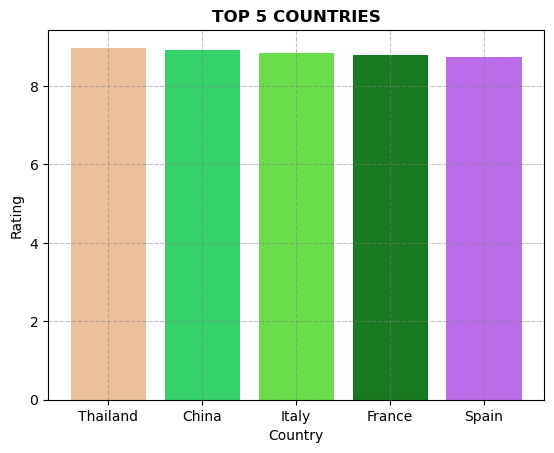

In [19]:
plt.figure()
patches = plt.bar(rating_per_country.index[0:5], rating_per_country["Ratings"][0:5])

for i in range(len(patches)):
   patches[i].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))

plt.grid(color='grey',linestyle='dashed', alpha=0.5)
plt.title('TOP 5 COUNTRIES', fontweight='bold')
plt.xlabel('Country')
plt.ylabel('Rating')
plt.show()

In [20]:
rating_per_studio = df.pivot_table(index="Animation Studio Name", values="Ratings", aggfunc="mean").sort_values(by="Ratings", ascending=False)
print(round(rating_per_studio, 2))

                       Ratings
Animation Studio Name         
Bones                     8.80
Madhouse                  8.78
Pierrot                   8.63
MAPPA                     8.63
Wit Studio                8.43
A-1 Pictures              8.05
Trigger                   8.03
Ufotable                  8.02
Toei Animation            7.73
Studio Ghibli             7.70


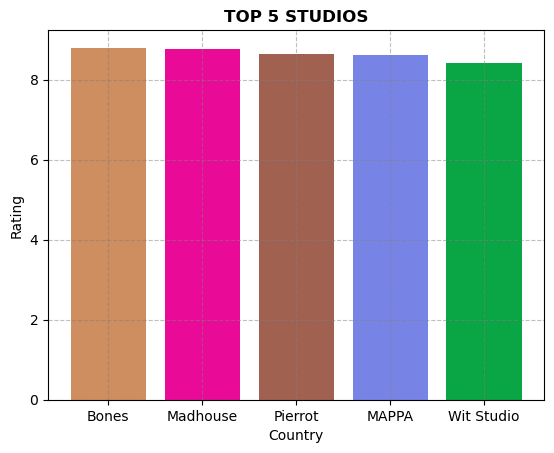

In [21]:
plt.figure()
patches = plt.bar(rating_per_studio.index[0:5], rating_per_studio["Ratings"][0:5])

for i in range(len(patches)):
   patches[i].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))

plt.grid(color='grey',linestyle='dashed', alpha=0.5)
plt.title('TOP 5 STUDIOS', fontweight='bold')
plt.xlabel('Country')
plt.ylabel('Rating')
plt.show()

In [22]:
total_spent = df.pivot_table(index="Animation Studio Name", values="Budget (in Million USD)", aggfunc="sum").sort_values(by="Budget (in Million USD)", ascending=False)
print(round(total_spent, 2))

                       Budget (in Million USD)
Animation Studio Name                         
Trigger                                 848.31
Bones                                   803.23
Madhouse                                781.87
Studio Ghibli                           770.76
MAPPA                                   741.39
Ufotable                                550.34
Wit Studio                              327.98
Toei Animation                          289.84
Pierrot                                 135.46
A-1 Pictures                            112.93


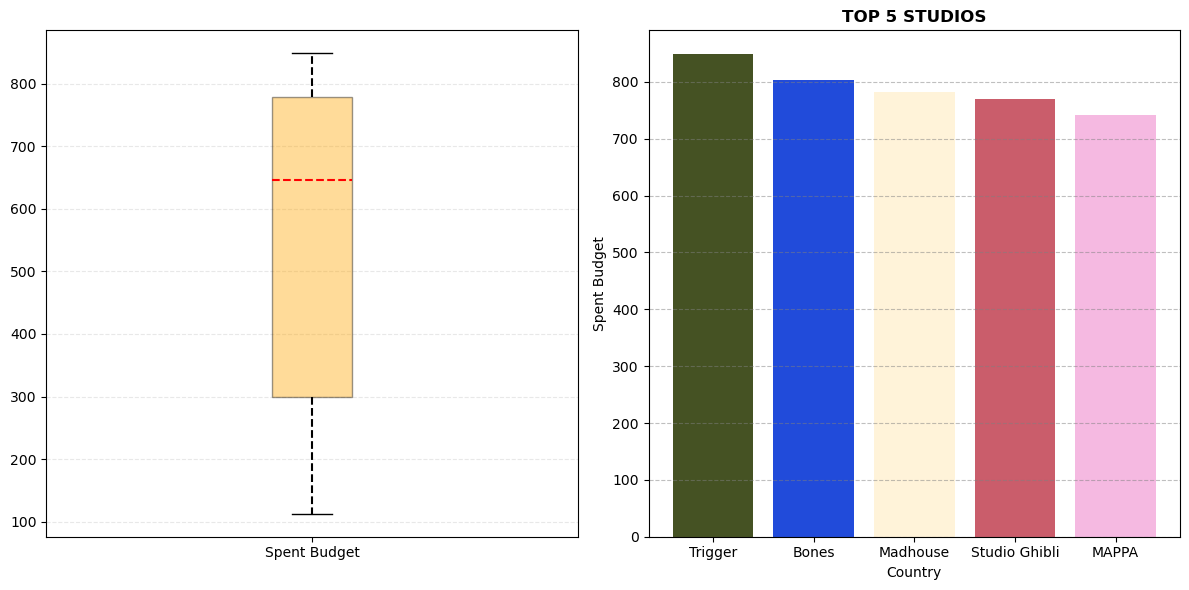

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

medianprops = dict(linestyle='dashed', linewidth=1.5, color='r') # firebrick
whiskerprops = dict(linestyle='--', linewidth=1.5)
boxprops = dict(facecolor='orange', alpha=0.4) 
ax[0].boxplot(total_spent,
               medianprops=medianprops,
               whiskerprops=whiskerprops,
               patch_artist=True,
               boxprops=boxprops)
ax[0].yaxis.grid(True,
              linestyle='dashed',
              color='lightgrey',
              alpha=0.5)
ax[0].set_xticklabels(['Spent Budget'])


patches = ax[1].bar(total_spent.index[0:5], total_spent["Budget (in Million USD)"][0:5])

for i in range(len(patches)):
   patches[i].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))

ax[1].yaxis.grid(color='grey',linestyle='dashed', alpha=0.5)
ax[1].set_title('TOP 5 STUDIOS', fontweight='bold')
ax[1].set_xlabel('Country')
ax[1].set_ylabel('Spent Budget')

plt.tight_layout()
plt.show()

In [24]:
average_rating = df.pivot_table(index="Animation Studio Name", values="Ratings", aggfunc="mean")
print(round(average_rating, 2))

                       Ratings
Animation Studio Name         
A-1 Pictures              8.05
Bones                     8.80
MAPPA                     8.63
Madhouse                  8.78
Pierrot                   8.63
Studio Ghibli             7.70
Toei Animation            7.73
Trigger                   8.03
Ufotable                  8.02
Wit Studio                8.43


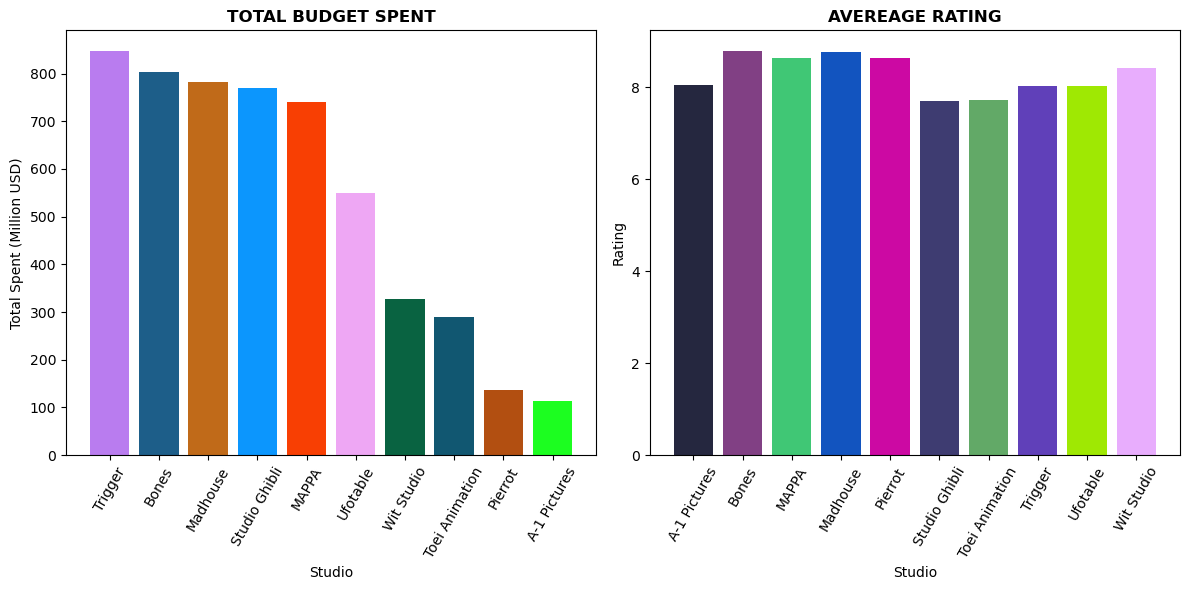

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

patches = ax[0].bar(total_spent.index, total_spent["Budget (in Million USD)"])

# Random facecolor for each bar
for i in range(len(patches)):
   patches[i].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))

ax[0].set_xticklabels(total_spent.index, rotation = 60)
ax[0].set_title('TOTAL BUDGET SPENT', fontweight='bold')
ax[0].set_xlabel('Studio')
ax[0].set_ylabel('Total Spent (Million USD)')

patches = ax[1].bar(average_rating.index, average_rating["Ratings"])

# Random facecolor for each bar
for i in range(len(patches)):
   patches[i].set_facecolor("#" + ''.join(random.choices("ABCDEF" + string.digits, k=6)))

ax[1].set_xticklabels(average_rating.index, rotation = 60)
ax[1].set_title('AVEREAGE RATING', fontweight='bold')
ax[1].set_xlabel('Studio')
ax[1].set_ylabel('Rating')

plt.tight_layout()
plt.show()